<img src="https://hilpisch.com/tpq_logo.png" alt="The Python Quants" width="35%" align="right" border="0"><br>

# Synthetic Financial Time Series

**Sequential GAN: LSTM Generator with Per-Step Noise and CNN Discriminator (PyTorch)**

&copy; Dr. Yves J. Hilpisch

<a href="https://tpq.io" target="_blank">https://tpq.io</a> | <a href="https://twitter.com/dyjh" target="_blank">@dyjh</a> | <a href="mailto:team@tpq.io">team@tpq.io</a>

## Imports & Settings

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from pylab import plt, mpl

In [2]:
import torch

In [3]:
sys.path.insert(0, os.path.abspath('..'))
from synthts.data import load_eod, compute_log_returns, ReturnScaler
from synthts.sequential import (SeqGenerator, SeqDiscriminator,
    train_seq_gan, generate_sequences)
from synthts.evaluate import (ks_test, ks_test_batch, pass_rate,
    describe_comparison, plot_histograms, plot_sorted,
    plot_pvalue_histogram,
    compare_acf, plot_acf_comparison, plot_drawdown_comparison)

In [4]:
plt.style.use('seaborn-v0_8')
mpl.rcParams['font.family'] = 'serif'

## Data Preparation

In [5]:
prices = load_eod(symbol='GLD', n_obs=2 * 252)
rets = compute_log_returns(prices)
scaler = ReturnScaler()
rets_ = scaler.fit_transform(rets)

In [6]:
f'Returns: {len(rets)} observations'

'Returns: 503 observations'

## Model Training

The sequential GAN uses an LSTM generator with **per-step noise**
(global latent + independent noise at each time step) and a
**1-D CNN discriminator** with spectral normalisation.
Training uses one-sided label smoothing and multiple generator
steps per discriminator step to keep the generator competitive.

In [7]:
SEQ_LEN = 63  #  # 3-month window
LATENT_DIM = 4
NOISE_DIM = 2
HU_GEN = 48
HU_DISC = 32

In [8]:
g = SeqGenerator(latent_dim=LATENT_DIM, noise_dim=NOISE_DIM,
                 hidden_units=HU_GEN, output_dim=1,
                 seq_len=SEQ_LEN, num_layers=1)
d = SeqDiscriminator(input_dim=1, hidden_units=HU_DISC)

In [9]:
%%time
history = train_seq_gan(
    g, d, rets_.reshape(-1, 1),
    seq_len=SEQ_LEN, epochs=5001, batch_size=64,
    lr_d=0.0001, lr_g=0.0002, latent_dim=LATENT_DIM,
    label_smooth=0.1, n_gen_steps=2,
    seed=100, log_interval=1000
)

Epoch     0 | D_real: 0.7371 D_fake: 0.6553 G: 0.7248
Epoch  1000 | D_real: 0.7758 D_fake: 0.5997 G: 0.7962
Epoch  2000 | D_real: 0.7776 D_fake: 0.5982 G: 0.7985
Epoch  3000 | D_real: 0.7752 D_fake: 0.5994 G: 0.7966
Epoch  4000 | D_real: 0.7810 D_fake: 0.5911 G: 0.8075
Epoch  5000 | D_real: 0.7734 D_fake: 0.6002 G: 0.7959
CPU times: user 4min 4s, sys: 1min 6s, total: 5min 10s
Wall time: 3min 1s


## Generating Synthetic Sequences

In [10]:
N = 25
seqs = generate_sequences(g, N, latent_dim=LATENT_DIM)
seqs.shape

(25, 63, 1)

In [11]:
# flatten all sequences for marginal distribution comparison
synth_flat = scaler.inverse_transform(
    seqs[:, :, 0].flatten())
f'Flattened synthetic observations: {len(synth_flat)}'

'Flattened synthetic observations: 1575'

### Marginal Distribution

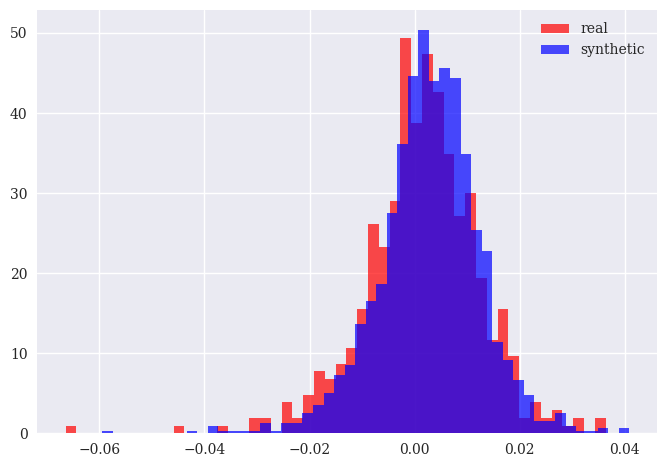

In [12]:
plot_histograms(rets, synth_flat);

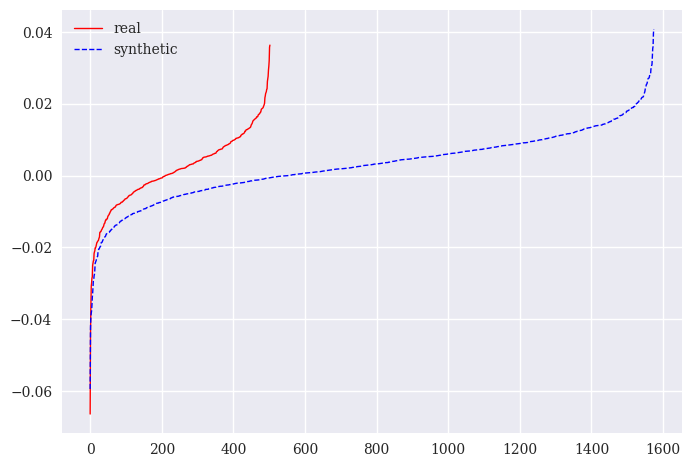

In [13]:
plot_sorted(rets, synth_flat);

In [14]:
print(f'Mean  | Real: {rets.mean():.6f}  Synth: {synth_flat.mean():.6f}')
print(f'Std   | Real: {rets.std():.6f}  Synth: {synth_flat.std():.6f}')
print(f'Min   | Real: {rets.min():.6f}  Synth: {synth_flat.min():.6f}')
print(f'Max   | Real: {rets.max():.6f}  Synth: {synth_flat.max():.6f}')

AttributeError: 'numpy.ndarray' object has no attribute 'describe'

In [ ]:
ks_result = ks_test(rets, synth_flat)
f'KS p-value: {ks_result["pvalue"]:.4f}'

### KS Batch Test

In [ ]:
N_BATCH = 100
batch_seqs = generate_sequences(g, N_BATCH, latent_dim=LATENT_DIM)
batch_df = pd.DataFrame()
for i in range(N_BATCH):
    batch_df[f'synth_{i}'] = scaler.inverse_transform(
        batch_seqs[i, :, 0])
pvals = ks_test_batch(rets, batch_df)
f'KS pass rate: {pass_rate(pvals):.0%}'

In [ ]:
plot_pvalue_histogram(pvals);

### Autocorrelation Comparison

In [ ]:
comp = compare_acf(rets, synth_flat, max_lag=10)
f'ACF diff: {comp["acf_diff"]:.4f}, Sq-return ACF diff: {comp["acf2_diff"]:.4f}'

In [ ]:
plot_acf_comparison(rets, synth_flat, max_lag=10);

### Cumulative Returns

In [ ]:
n_show = min(10, N)
fig, ax = plt.subplots()
# real cumulative path
ax.plot(np.cumsum(rets), 'r', lw=2, label='real')
# synthetic cumulative paths (each 63 steps)
for i in range(n_show):
    s = scaler.inverse_transform(seqs[i, :, 0])
    ax.plot(np.arange(SEQ_LEN), np.cumsum(s),
            'b--', lw=0.7, label='_nolegend_')
ax.plot([], [], 'b--', lw=0.7, label='synthetic')
ax.legend();
ax.set_title('Cumulative Returns');
ax.set_xlabel('Day');
ax.set_ylabel('Cumulative Return');

### Drawdown Comparison

In [ ]:
plot_drawdown_comparison(rets, synth_flat);

## Summary

The sequential GAN with an LSTM generator (per-step noise)
and a 1-D CNN discriminator with spectral normalisation
produces stable training dynamics.  The generator produces
return sequences with realistic marginal statistics
(mean, std) and reasonable temporal structure.  The approach
is more challenging than the dense (vanilla/WGAN-GP) models
because the discriminator can exploit temporal patterns,
but the CNN architecture provides a good balance between
discriminative power and training stability.

In [ ]:
print(f'Mean  | Real: {rets.mean():.6f}  Synth: {synth_flat.mean():.6f}')
print(f'Std   | Real: {rets.std():.6f}  Synth: {synth_flat.std():.6f}')
print(f'KS p  | {ks_result["pvalue"]:.4f}')
print(f'ACF   | diff={comp["acf_diff"]:.4f}  sq-ret diff={comp["acf2_diff"]:.4f}')